# Descriptive Analysis

**Master's thesis:** From Dyads to Networks: Vendor Lock-in and Systemic Vulnerability in German Public IT Procurement

**Author:** Marco Stoehr

**Notebook:** 3 of 5 (run in order; see README)

**Thesis sections:** 3.2, 4.1, Appendix B.1 and B.2

## Purpose
This notebook contains the first part of the analysis. It describes the structure of the procurement networks before the panel regression and the resilience analysis and establishes whether contracting authorities award repeatedly to the same suppliers. It consists of two parts:

1. **General descriptives:** network size over time, degree distributions, tie persistence, repeat-tie share and market concentration.
2. **Network structure:** filtered bipartite networks (dyads active in at least two years), component structure and network visualizations.

## Input
- `data_analysis/dyad_years.csv`

## Main Output
- `graphs_tables/`
- `results/`

In [1]:
# load packages
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
import numpy as np
import networkx as nx
from matplotlib.patches import Patch

In [2]:
# -----------------------------------------------------------
# Load dyad-year panel
# -----------------------------------------------------------
df = pd.read_csv("data_analysis/dyad_years.csv")

print(f"Rows: {len(df):,}")
print(f"Years: {df['YEAR'].min()}–{df['YEAR'].max()}")
print(f"Segments: {df['cpv_segments_str'].unique()}")

Rows: 37,775
Years: 2009–2023
Segments: <ArrowStringArray>
['30', '72', '48', '48|72', '30|48', '30|72', '30|48|72']
Length: 7, dtype: str


In [3]:
# --- Segment display settings ---------------------------------------------
# Colour, line style and marker are set together so that every figure uses the
# same encoding. Line style and marker keep the segments distinguishable in
# greyscale print; the palette is ColorBrewer Dark2, which is checked for
# colour vision deficiency.
seg_labels = {"30": "Hardware", "48": "Software", "72": "IT Services"}
seg_colors = {"30": "#1b9e77", "48": "#d95f02", "72": "#7570b3"}
seg_styles = {"30": "-", "48": "--", "72": ":"}
seg_markers = {"30": "o", "48": "s", "72": "^"}

## Part I - General descriptive analysis
Step I: Network size over time

In [4]:
# -----------------------------------------------------------
# Network size per segment-year ("contains" logic)
# -----------------------------------------------------------
records = []

for seg in ["30", "48", "72"]:
    seg_df = df[df["cpv_segments_str"].str.contains(seg)]
    for yr, grp in seg_df.groupby("YEAR"):
        records.append({
            "segment": seg,
            "year": yr,
            "n_buyers": grp["CAE_NAME_CANONICAL"].nunique(),
            "n_suppliers": grp["WIN_NAME_FINAL"].nunique(),
            "n_edges": len(grp),
        })

net_size = pd.DataFrame(records).sort_values(["segment", "year"])
net_size["suppliers_per_buyer"] = (
    net_size["n_suppliers"] / net_size["n_buyers"]
).round(2)
net_size["edges_per_buyer"] = (
    net_size["n_edges"] / net_size["n_buyers"]
).round(2)
net_size.head(15)

,segment,year,n_buyers,n_suppliers,n_edges,suppliers_per_buyer,edges_per_buyer
0,30,2009,280,263,510,0.94,1.82
1,30,2010,287,284,526,0.99,1.83
2,30,2011,280,299,550,1.07,1.96
3,30,2012,297,326,583,1.10,1.96
4,30,2013,310,353,637,1.14,2.05
5,30,2014,314,314,589,1.00,1.88
6,30,2015,363,346,665,0.95,1.83
7,30,2016,431,355,768,0.82,1.78
8,30,2017,470,393,974,0.84,2.07
9,30,2018,472,378,842,0.80,1.78


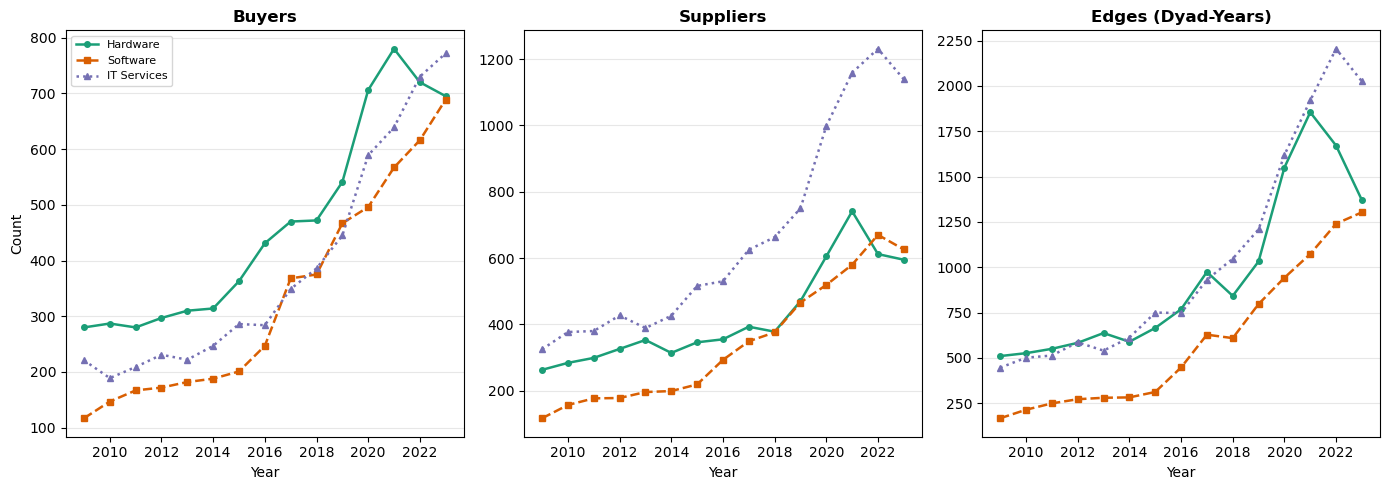

In [5]:
# -----------------------------------------------------------
# Plot: network size over time (1 x 3)
# -----------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(14, 5), sharey=False)
metrics = [("n_buyers", "Buyers"), ("n_suppliers", "Suppliers"), ("n_edges", "Edges (Dyad-Years)")]

for ax, (col, title) in zip(axes, metrics):
    for seg in ["30", "48", "72"]:
        sub = net_size[net_size["segment"] == seg]
        ax.plot(sub["year"], sub[col],
                label=seg_labels[seg],
                color=seg_colors[seg],
                linestyle=seg_styles[seg],
                marker=seg_markers[seg],
                markersize=4, linewidth=1.8)
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel("Year")
    ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    ax.grid(axis="y", alpha=0.3)

axes[0].set_ylabel("Count")
axes[0].legend(fontsize=8, loc="upper left")

# fig.suptitle("Network Size by Segment and Year (2009–2023)", fontsize=18, fontweight="bold", y=1.02)
fig.tight_layout()
plt.savefig("graphs_tables/desc_network_size_over_time.pdf", dpi=200, bbox_inches="tight")
plt.show()

Step II: Degre-Distribution

In [6]:
# -----------------------------------------------------------
# Degree distributions per segment (aggregated 2017–2023)
# -----------------------------------------------------------
df17 = df[df["YEAR"].between(2017, 2023)]

degree_data = {}

for seg in ["30", "48", "72"]:
    seg_df = df17[df17["cpv_segments_str"].str.contains(seg)]
    
    # Buyer degree = number of distinct suppliers
    buyer_deg = seg_df.groupby("CAE_NAME_CANONICAL")["WIN_NAME_FINAL"].nunique()
    buyer_deg.name = "degree"
    
    # Supplier degree = number of distinct buyers
    supplier_deg = seg_df.groupby("WIN_NAME_FINAL")["CAE_NAME_CANONICAL"].nunique()
    supplier_deg.name = "degree"
    
    degree_data[seg] = {"buyer": buyer_deg, "supplier": supplier_deg}
    
    print(f"CPV {seg}: Buyers={len(buyer_deg):,}  Suppliers={len(supplier_deg):,}")
    print(f"  Buyer degree:   mean={buyer_deg.mean():.2f}  median={buyer_deg.median():.0f}  max={buyer_deg.max()}")
    print(f"  Supplier degree: mean={supplier_deg.mean():.2f}  median={supplier_deg.median():.0f}  max={supplier_deg.max()}")
    print()

CPV 30: Buyers=2,353  Suppliers=2,250
  Buyer degree:   mean=3.36  median=2  max=68
  Supplier degree: mean=3.52  median=1  max=479

CPV 48: Buyers=2,013  Suppliers=2,355
  Buyer degree:   mean=2.92  median=1  max=93
  Supplier degree: mean=2.50  median=1  max=217

CPV 72: Buyers=2,116  Suppliers=4,257
  Buyer degree:   mean=4.33  median=1  max=232
  Supplier degree: mean=2.15  median=1  max=143



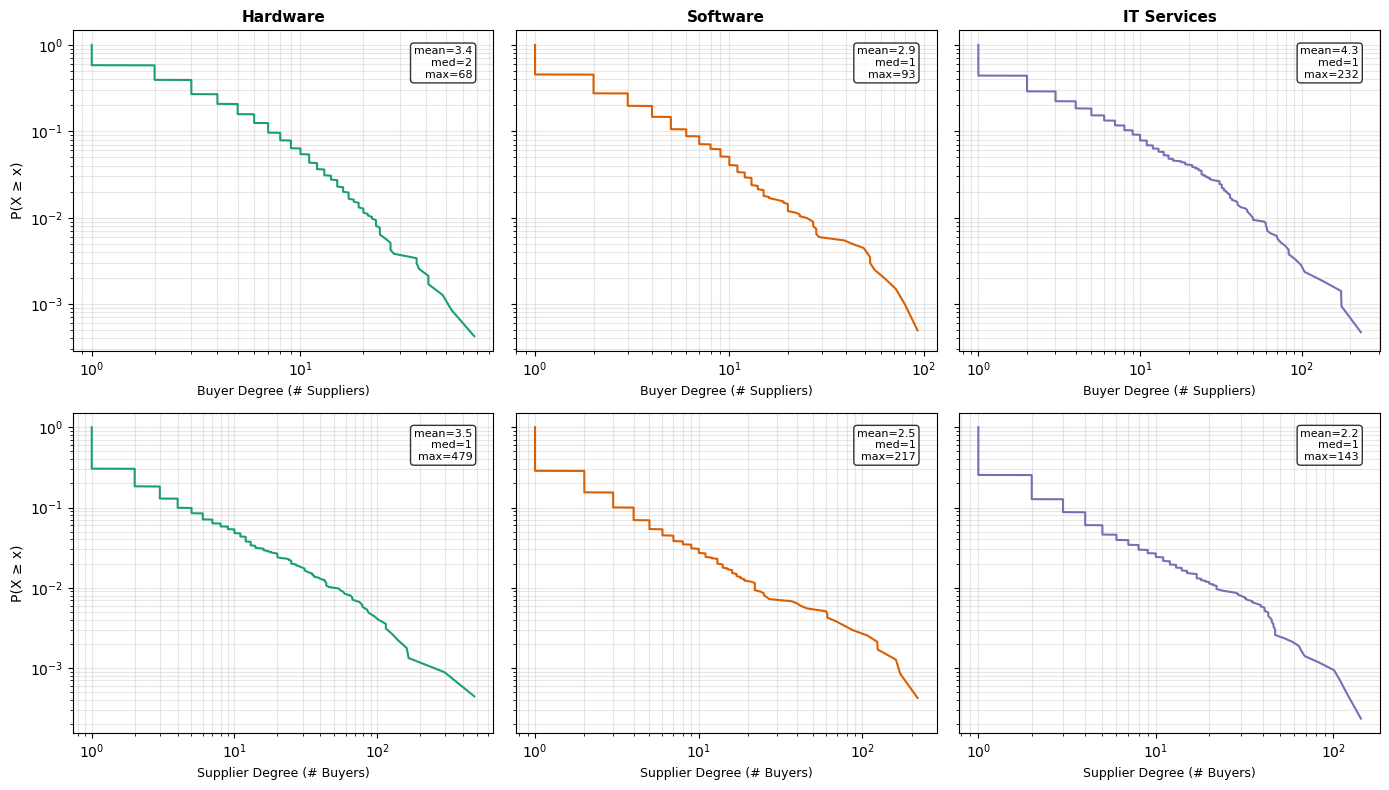

In [7]:
# -----------------------------------------------------------
# Plot: CCDF of degree distributions (2 x 3: buyer/supplier × segment)
# -----------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharey="row")

sides = ["buyer", "supplier"]
side_labels = {"buyer": "Buyer Degree (# Suppliers)", "supplier": "Supplier Degree (# Buyers)"}

for row, side in enumerate(sides):
    for col, seg in enumerate(["30", "48", "72"]):
        ax = axes[row, col]
        deg = degree_data[seg][side]
        
        # CCDF: P(X >= x)
        sorted_deg = np.sort(deg.values)
        ccdf = 1 - np.arange(0, len(sorted_deg)) / len(sorted_deg)
        
        ax.plot(sorted_deg, ccdf, color=seg_colors[seg], linewidth=1.5)
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xlabel(side_labels[side], fontsize=9)
        ax.grid(True, alpha=0.3, which="both")
        
        # Annotate summary stats
        ax.text(0.95, 0.95, f"mean={deg.mean():.1f}\nmed={deg.median():.0f}\nmax={deg.max()}",
                transform=ax.transAxes, fontsize=8, va="top", ha="right",
                bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))
        
        if row == 0:
            ax.set_title(seg_labels[seg], fontsize=11, fontweight="bold")
    
    axes[row, 0].set_ylabel("P(X ≥ x)", fontsize=10)

# fig.suptitle("Degree Distributions – CCDF (2017–2023, log-log)", fontsize=13, fontweight="bold", y=1.02)
fig.tight_layout()
plt.savefig("graphs_tables/desc_degree_distributions_ccdf.pdf", dpi=200, bbox_inches="tight")
plt.show()

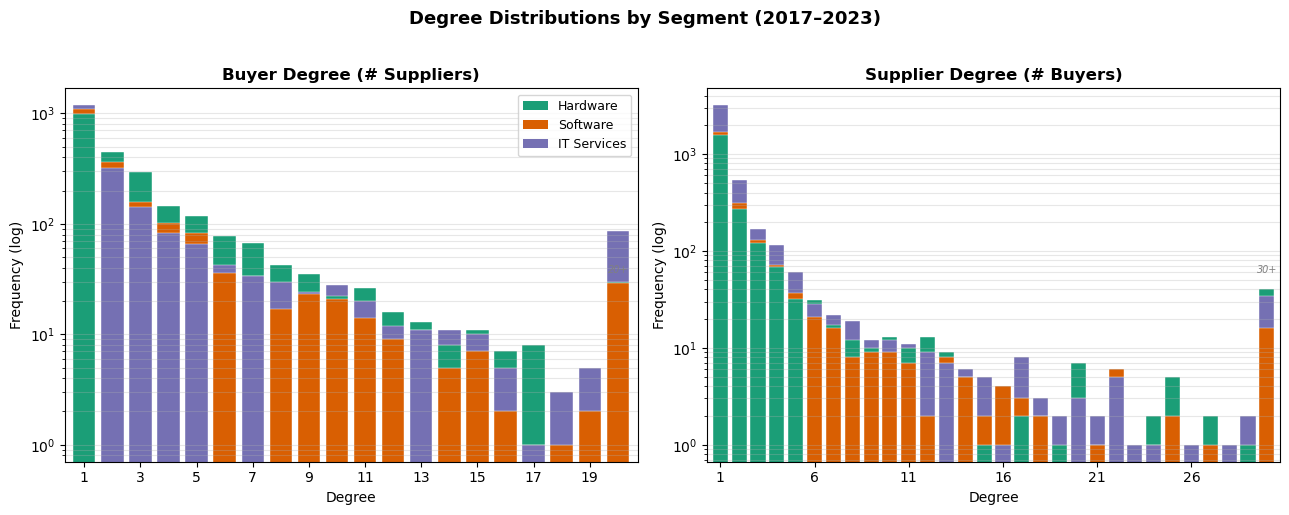

In [8]:
# -----------------------------------------------------------
# Plot: Degree histograms, layered back-to-front, log-y (1 x 2)
# -----------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sides = ["buyer", "supplier"]
side_titles = {"buyer": "Buyer Degree (# Suppliers)", "supplier": "Supplier Degree (# Buyers)"}
x_caps = {"buyer": 20, "supplier": 30}

for ax, side in zip(axes, sides):
    cap = x_caps[side]
    x_vals = np.arange(1, cap + 1)
    
    # Compute counts per segment
    seg_counts = {}
    for seg in ["30", "48", "72"]:
        deg = degree_data[seg][side]
        counts = []
        for d in x_vals:
            if d < cap:
                counts.append((deg == d).sum())
            else:
                counts.append((deg >= d).sum())
        seg_counts[seg] = np.array(counts)
    
    # For each degree: sort segments by count descending → plot tallest first
    for i, d in enumerate(x_vals):
        vals = {seg: seg_counts[seg][i] for seg in ["30", "48", "72"]}
        for seg, _ in sorted(vals.items(), key=lambda x: x[1], reverse=True):
            ax.bar(d, vals[seg], width=0.8, color=seg_colors[seg],
                   edgecolor="white", linewidth=0.3)
    
    ax.set_yscale("log")
    ax.set_title(side_titles[side], fontsize=12, fontweight="bold")
    ax.set_xlabel("Degree")
    ax.set_ylabel("Frequency (log)")
    ax.set_xlim(0.3, cap + 0.7)
    ax.set_xticks(np.arange(1, cap + 1, 2 if cap <= 20 else 5))
    ax.grid(axis="y", alpha=0.3, which="both")
    
    ax.text(cap, 0.5, f"{cap}+", transform=ax.get_xaxis_transform(),
            fontsize=7, ha="center", va="bottom", color="grey", style="italic")

# Manual legend (since per-bar plotting duplicates labels)
legend_elements = [Patch(facecolor=seg_colors[s], label=seg_labels[s]) for s in ["30", "48", "72"]]
axes[0].legend(handles=legend_elements, fontsize=9)

fig.suptitle("Degree Distributions by Segment (2017–2023)", fontsize=13, fontweight="bold", y=1.02)
fig.tight_layout()
plt.savefig("graphs_tables/desc_degree_distributions_hist.png", dpi=200, bbox_inches="tight")
plt.show()

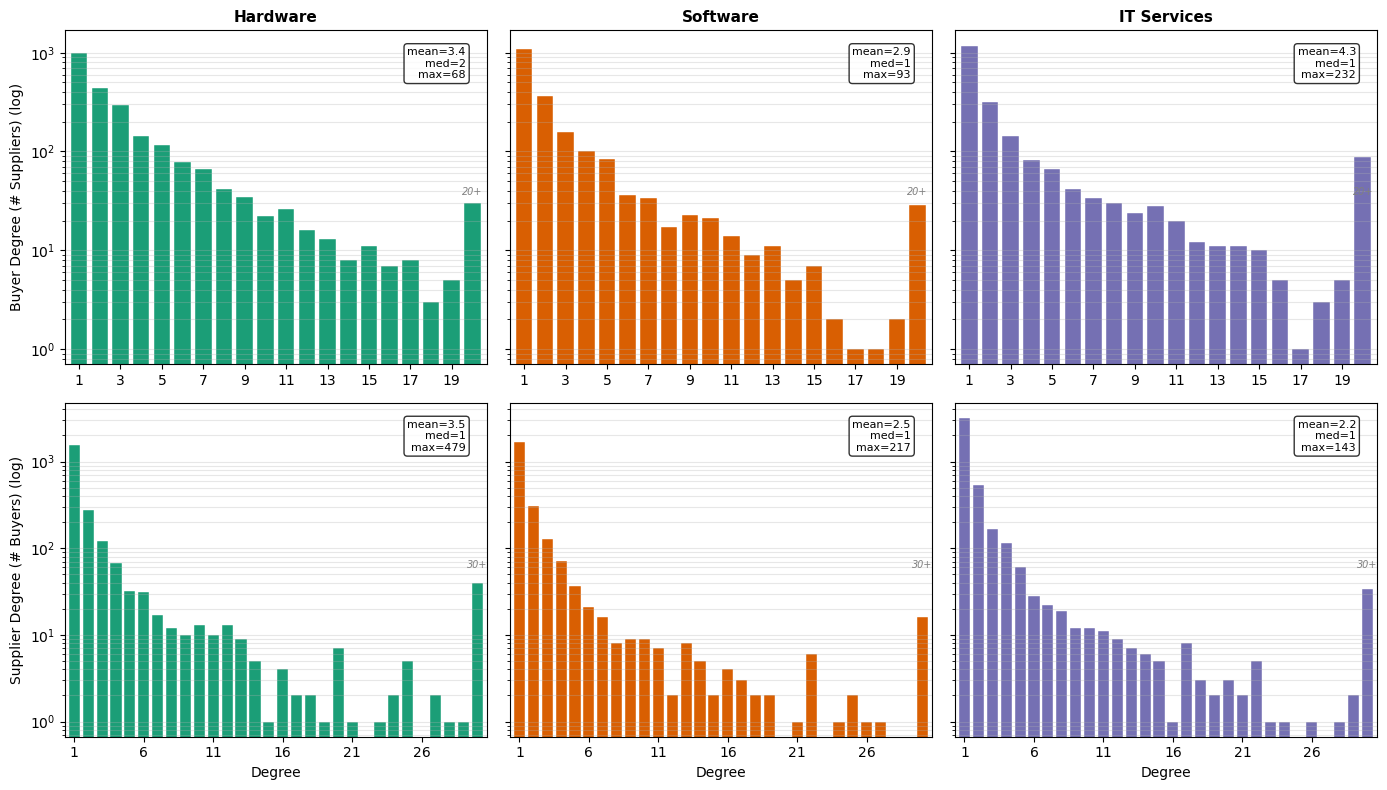

In [9]:
# -----------------------------------------------------------
# Plot: Degree distributions, 2x3 grid (buyer/supplier × segment)
# -----------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharey="row")

sides = ["buyer", "supplier"]
side_ylabels = {"buyer": "Buyer Degree (# Suppliers) (log)", "supplier": "Supplier Degree (# Buyers) (log)"}
x_caps = {"buyer": 20, "supplier": 30}

for row, side in enumerate(sides):
    cap = x_caps[side]
    x_vals = np.arange(1, cap + 1)
    
    for col, seg in enumerate(["30", "48", "72"]):
        ax = axes[row, col]
        deg = degree_data[seg][side]
        
        counts = []
        for d in x_vals:
            if d < cap:
                counts.append((deg == d).sum())
            else:
                counts.append((deg >= d).sum())
        
        ax.bar(x_vals, counts, width=0.8, color=seg_colors[seg],
               edgecolor="white", linewidth=0.3)
        
        ax.set_yscale("log")
        ax.set_xlim(0.3, cap + 0.7)
        ax.set_xticks(np.arange(1, cap + 1, 2 if cap <= 20 else 5))
        ax.grid(axis="y", alpha=0.3, which="both")
        
        # Summary stats
        ax.text(0.95, 0.95, f"mean={deg.mean():.1f}\nmed={deg.median():.0f}\nmax={deg.max():,}",
                transform=ax.transAxes, fontsize=8, va="top", ha="right",
                bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))
        
        ax.text(cap, 0.5, f"{cap}+", transform=ax.get_xaxis_transform(),
                fontsize=7, ha="center", va="bottom", color="grey", style="italic")
        
        if row == 0:
            ax.set_title(seg_labels[seg], fontsize=11, fontweight="bold")
        if col == 0:
            ax.set_ylabel(side_ylabels[side], fontsize=10)
        if row == 1:
            ax.set_xlabel("Degree")

# fig.suptitle("Degree Distributions by Segment (2017–2023)", fontsize=18, fontweight="bold", y=1.02)
fig.tight_layout()
plt.savefig("graphs_tables/desc_degree_distributions_hist_sep.pdf", dpi=200, bbox_inches="tight")
plt.show()

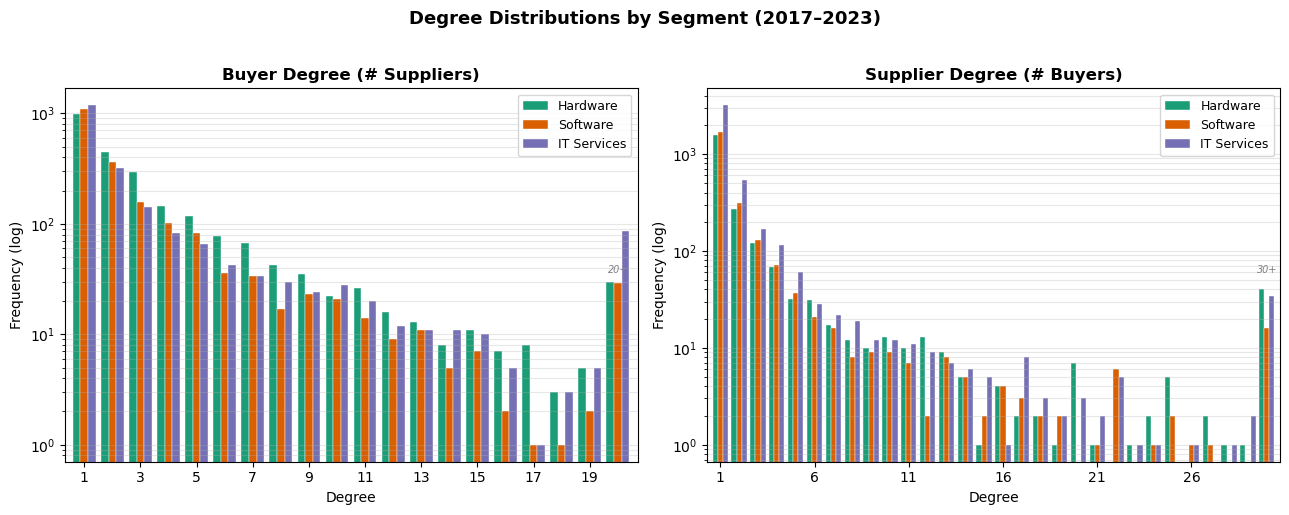

In [10]:
# -----------------------------------------------------------
# Plot: Degree histograms, dodged bars, log-y (1 x 2)
# -----------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sides = ["buyer", "supplier"]
side_titles = {"buyer": "Buyer Degree (# Suppliers)", "supplier": "Supplier Degree (# Buyers)"}
x_caps = {"buyer": 20, "supplier": 30}
bar_width = 0.27
offsets = {"30": -bar_width, "48": 0, "72": bar_width}

for ax, side in zip(axes, sides):
    cap = x_caps[side]
    x_vals = np.arange(1, cap + 1)
    
    for seg in ["30", "48", "72"]:
        deg = degree_data[seg][side]
        # Count per degree, cap last bin
        counts = []
        for d in x_vals:
            if d < cap:
                counts.append((deg == d).sum())
            else:
                counts.append((deg >= d).sum())  # last bin = "cap+"
        
        ax.bar(x_vals + offsets[seg], counts, width=bar_width,
               label=seg_labels[seg], color=seg_colors[seg],
               edgecolor="white", linewidth=0.3)
    
    ax.set_yscale("log")
    ax.set_title(side_titles[side], fontsize=12, fontweight="bold")
    ax.set_xlabel("Degree")
    ax.set_ylabel("Frequency (log)")
    ax.set_xlim(0.3, cap + 0.7)
    ax.set_xticks(np.arange(1, cap + 1, 2 if cap <= 20 else 5))
    ax.legend(fontsize=9)
    ax.grid(axis="y", alpha=0.3, which="both")
    
    # Label last bin
    ax.text(cap, 0.5, f"{cap}+", transform=ax.get_xaxis_transform(),
            fontsize=7, ha="center", va="bottom", color="grey", style="italic")

fig.suptitle("Degree Distributions by Segment (2017–2023)", fontsize=13, fontweight="bold", y=1.02)
fig.tight_layout()
plt.savefig("graphs_tables/desc_degree_distributions_hist_3bars.png", dpi=200, bbox_inches="tight")
plt.show()

Step III: Repeated tie share 

In [11]:
# -----------------------------------------------------------
# Repeat-tie share per segment-year
# -----------------------------------------------------------
records_rt = []

for seg in ["30", "48", "72"]:
    seg_df = df[df["cpv_segments_str"].str.contains(seg)]
    for yr, grp in seg_df.groupby("YEAR"):
        n_dyads = len(grp)
        n_repeat = (grp["ever_tied_ijt"] == 1).sum()
        records_rt.append({
            "segment": seg,
            "year": yr,
            "n_dyads": n_dyads,
            "n_repeat": n_repeat,
            "repeat_share": n_repeat / n_dyads if n_dyads > 0 else 0,
        })

repeat_ties = pd.DataFrame(records_rt)
repeat_ties[repeat_ties["year"] >= 2017].pivot(index="year", columns="segment", values="repeat_share").round(3)

segment,30,48,72
year,,,
2017,0.208,0.188,0.218
2018,0.277,0.194,0.264
2019,0.260,0.177,0.266
2020,0.174,0.205,0.245
2021,0.212,0.217,0.265
2022,0.242,0.224,0.239
2023,0.288,0.209,0.301


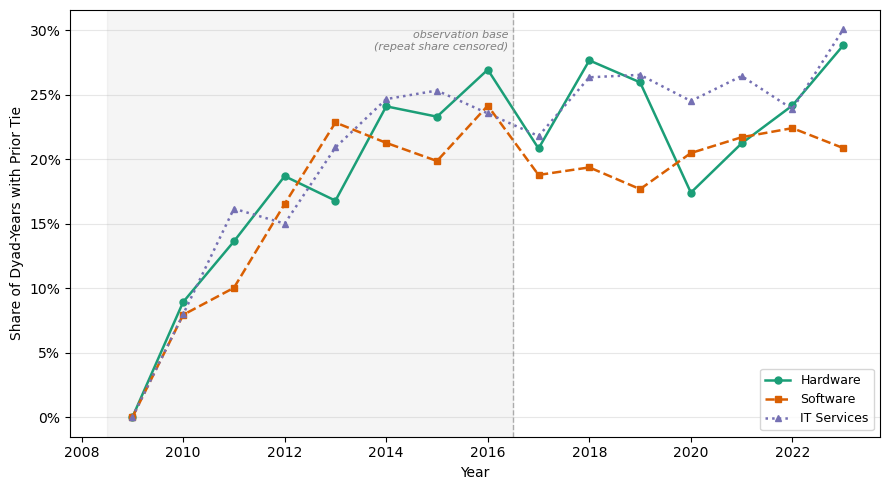

In [12]:
# -----------------------------------------------------------
# Plot: Repeat-tie share over time
# -----------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 5))

for seg in ["30", "48", "72"]:
    sub = repeat_ties[repeat_ties["segment"] == seg]
    ax.plot(sub["year"], sub["repeat_share"],
            label=seg_labels[seg],
            color=seg_colors[seg],
            linestyle=seg_styles[seg],
            marker=seg_markers[seg],
            markersize=5, linewidth=1.8)

ax.axvspan(2008.5, 2016.5, color="grey", alpha=0.08, zorder=0)
ax.axvline(x=2016.5, color="grey", linestyle="--", linewidth=1, alpha=0.6)
ax.text(2016.4, ax.get_ylim()[1] * 0.95,
        "observation base\n(repeat share censored)", fontsize=8,
        ha="right", va="top", color="grey", style="italic")

ax.set_xlabel("Year")
ax.set_ylabel("Share of Dyad-Years with Prior Tie")
# ax.set_title("Repeat-Tie Share by Segment (2009–2023)", fontsize=18, fontweight="bold")
ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
ax.legend(fontsize=9)
ax.grid(axis="y", alpha=0.3)


fig.tight_layout()
plt.savefig("graphs_tables/desc_repeat_tie_share.pdf", dpi=200, bbox_inches="tight")
plt.show()

In [13]:
# -----------------------------------------------------------
# Summary table: key network descriptives per segment (2017–2023)
# -----------------------------------------------------------
df17 = df[df["YEAR"].between(2017, 2023)]
summary_records = []

for seg in ["30", "48", "72"]:
    seg_df = df17[df17["cpv_segments_str"].str.contains(seg)]
    
    buyers = seg_df["CAE_NAME_CANONICAL"].unique()
    suppliers = seg_df["WIN_NAME_FINAL"].unique()
    n_buyers = len(buyers)
    n_suppliers = len(suppliers)
    
    # Edges = unique dyads (not dyad-years)
    edges = seg_df.groupby(["CAE_NAME_CANONICAL", "WIN_NAME_FINAL"]).ngroups
    
    # Density (bipartite): edges / (n_buyers * n_suppliers)
    density = edges / (n_buyers * n_suppliers)
    
    # Degrees
    buyer_deg = seg_df.groupby("CAE_NAME_CANONICAL")["WIN_NAME_FINAL"].nunique()
    supplier_deg = seg_df.groupby("WIN_NAME_FINAL")["CAE_NAME_CANONICAL"].nunique()
    
    # Build bipartite graph for component structure
    B = nx.Graph()
    for _, row in seg_df[["CAE_NAME_CANONICAL", "WIN_NAME_FINAL"]].drop_duplicates().iterrows():
        B.add_edge(f"B_{row['CAE_NAME_CANONICAL']}", f"S_{row['WIN_NAME_FINAL']}")
    
    components = list(nx.connected_components(B))
    n_components = len(components)
    gcc_size = len(max(components, key=len))
    gcc_share = gcc_size / B.number_of_nodes()
    
    # Repeat-tie share (analysis period only)
    repeat_share = seg_df["ever_tied_ijt"].mean()
    
    summary_records.append({
        "Segment": f"CPV {seg}",
        "Buyers": n_buyers,
        "Suppliers": n_suppliers,
        "Edges (unique dyads)": edges,
        "Density": round(density, 5),
        "Buyer Deg. Mean": round(buyer_deg.mean(), 2),
        "Buyer Deg. Median": int(buyer_deg.median()),
        "Supplier Deg. Mean": round(supplier_deg.mean(), 2),
        "Supplier Deg. Median": int(supplier_deg.median()),
        "Components": n_components,
        "GCC Share": round(gcc_share, 3),
        "Repeat-Tie Share": round(repeat_share, 3),
    })

summary_table = pd.DataFrame(summary_records).set_index("Segment")
summary_table.T

Segment,CPV 30,CPV 48,CPV 72
Buyers,2353.0000,2013.00000,2116.00000
Suppliers,2250.0000,2355.00000,4257.00000
Edges (unique dyads),7917.0000,5888.00000,9157.00000
Density,0.0015,0.00124,0.00102
Buyer Deg. Mean,3.3600,2.92000,4.33000
Buyer Deg. Median,2.0000,1.00000,1.00000
Supplier Deg. Mean,3.5200,2.50000,2.15000
Supplier Deg. Median,1.0000,1.00000,1.00000
Components,238.0000,362.00000,494.00000
GCC Share,0.8770,0.79300,0.80500


Step IV: Tie persistence

CPV 30: ≥1 years: 7,917 dyads (100.0%)
CPV 30: ≥2 years:   996 dyads (12.6%)
CPV 30: ≥3 years:   254 dyads (3.2%)
CPV 30: ≥4 years:    80 dyads (1.0%)
CPV 30: ≥5 years:    34 dyads (0.4%)
CPV 30: ≥6 years:    12 dyads (0.2%)
CPV 30: ≥7 years:     1 dyads (0.0%)

CPV 48: ≥1 years: 5,888 dyads (100.0%)
CPV 48: ≥2 years:   517 dyads (8.8%)
CPV 48: ≥3 years:   126 dyads (2.1%)
CPV 48: ≥4 years:    42 dyads (0.7%)
CPV 48: ≥5 years:    15 dyads (0.3%)
CPV 48: ≥6 years:     4 dyads (0.1%)
CPV 48: ≥7 years:     0 dyads (0.0%)

CPV 72: ≥1 years: 9,157 dyads (100.0%)
CPV 72: ≥2 years: 1,164 dyads (12.7%)
CPV 72: ≥3 years:   346 dyads (3.8%)
CPV 72: ≥4 years:   158 dyads (1.7%)
CPV 72: ≥5 years:    83 dyads (0.9%)
CPV 72: ≥6 years:    38 dyads (0.4%)
CPV 72: ≥7 years:    10 dyads (0.1%)



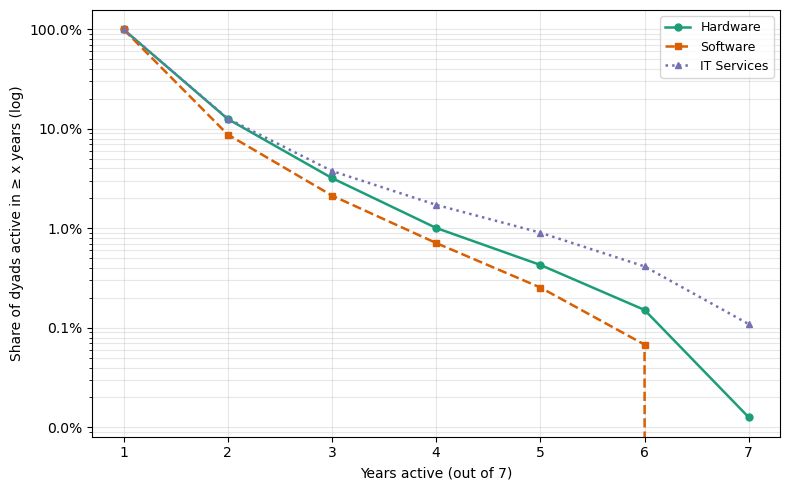

In [14]:
# -----------------------------------------------------------
# Tie persistence distribution per segment (2017–2023)
# -----------------------------------------------------------
df17 = df[df["YEAR"].between(2017, 2023)]

fig, ax = plt.subplots(figsize=(8, 5))
x_vals = np.arange(1, 8)

for seg in ["30", "48", "72"]:
    seg_df = df17[df17["cpv_segments_str"].str.contains(seg)]

    # Number of active years per dyad within the analysis period
    persistence = seg_df.groupby(["CAE_NAME_CANONICAL", "WIN_NAME_FINAL"]).size()
    total_dyads = len(persistence)

    cum_share = [(persistence >= x).mean() for x in x_vals]

    ax.plot(x_vals, cum_share,
            label=seg_labels[seg], color=seg_colors[seg],
            linestyle=seg_styles[seg], marker=seg_markers[seg],
            markersize=5, linewidth=1.8)

    for y in x_vals:
        n = (persistence >= y).sum()
        print(f"CPV {seg}: ≥{y} years: {n:>5,} dyads ({n/total_dyads:.1%})")
    print()

ax.set_yscale("log")
ax.set_xlabel("Years active (out of 7)")
ax.set_ylabel("Share of dyads active in ≥ x years (log)")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=1))
ax.set_xticks(x_vals)
ax.legend(fontsize=9)
ax.grid(alpha=0.3, which="both")
# ax.set_title("Tie Persistence by Segment (2017–2023)", fontsize=18, fontweight="bold")

fig.tight_layout()
plt.savefig("graphs_tables/desc_tie_persistence.pdf", dpi=200, bbox_inches="tight")
plt.show()

## Descriptive network analysis
In order to reduce complexity of the plotted networks and to ensure that the network structures and differences actually become visible, only filtered networks with edges between a buyer and a supplier in at least two years were plotted.

CPV 30: 68 components, GCC 647 nodes (79.9%), 46 isolated pairs (67.6% of components, 11.4% of nodes)
CPV 48: 52 components, GCC 351 nodes (74.5%), 45 isolated pairs (86.5% of components, 19.1% of nodes)
CPV 72: 97 components, GCC 701 nodes (75.8%), 76 isolated pairs (78.4% of components, 16.4% of nodes)


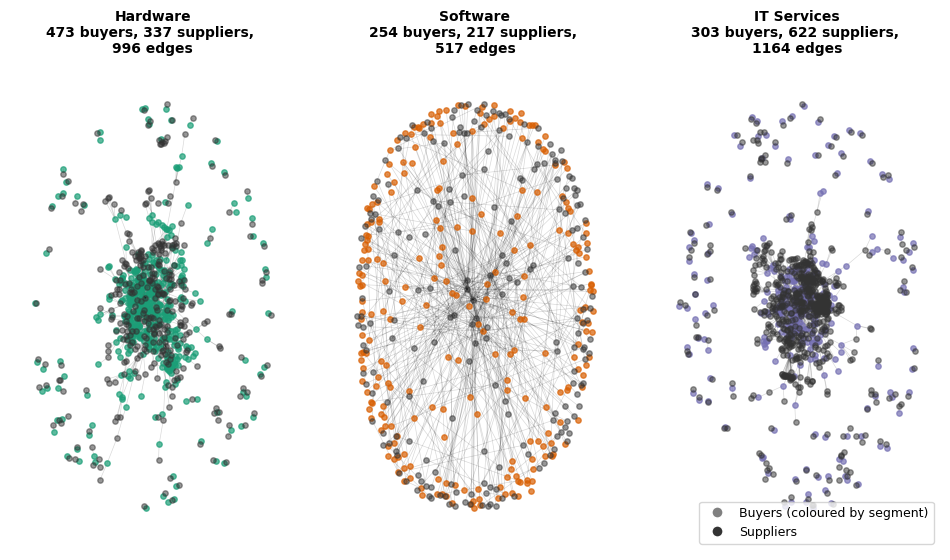

In [15]:
# -----------------------------------------------------------
# Filtered networks: dyads active ≥2 years (2017–2023)
# -----------------------------------------------------------
THRESHOLD = 2

fig, axes = plt.subplots(1, 3, figsize=(9.6, 5.7))

for ax, seg in zip(axes, ["30", "48", "72"]):
    seg_df = df17[df17["cpv_segments_str"].str.contains(seg)]
    
    # Identify persistent dyads
    persistence = seg_df.groupby(["CAE_NAME_CANONICAL", "WIN_NAME_FINAL"]).size()
    backbone_dyads = persistence[persistence >= THRESHOLD].reset_index()
    backbone_dyads.columns = ["buyer", "supplier", "n_years"]
    
    # Build bipartite graph
    B = nx.Graph()
    for _, row in backbone_dyads.iterrows():
        B.add_edge(f"B_{row['buyer']}", f"S_{row['supplier']}", weight=row["n_years"])
    
    # Node attributes
    buyers_in_graph = [n for n in B.nodes() if n.startswith("B_")]
    suppliers_in_graph = [n for n in B.nodes() if n.startswith("S_")]

    # Component structure of the filtered network: layout-invariant and therefore the
    # quantitative counterpart to what the figure shows qualitatively.
    comps = sorted(nx.connected_components(B), key=len, reverse=True)
    gcc_share = len(comps[0]) / B.number_of_nodes()
    n_isolated_pairs = sum(1 for c in comps if len(c) == 2)

    print(f"CPV {seg}: {len(comps)} components, "
          f"GCC {len(comps[0])} nodes ({gcc_share:.1%}), "
          f"{n_isolated_pairs} isolated pairs "
          f"({n_isolated_pairs/len(comps):.1%} of components, "
          f"{2*n_isolated_pairs/B.number_of_nodes():.1%} of nodes)")
    
    # Layout
    pos = nx.spring_layout(B, k=0.8, iterations=50, seed=42)
    
    # Draw
    nx.draw_networkx_edges(B, pos, ax=ax, alpha=0.15, width=0.5)
    nx.draw_networkx_nodes(B, pos, nodelist=buyers_in_graph, node_size=15,
                           node_color=seg_colors[seg], alpha=0.7, ax=ax)
    nx.draw_networkx_nodes(B, pos, nodelist=suppliers_in_graph, node_size=15,
                           node_color="#333333", alpha=0.5, ax=ax)
    
    ax.set_title(f"{seg_labels[seg]}\n{len(buyers_in_graph)} buyers, "
                 f"{len(suppliers_in_graph)} suppliers, \n{B.number_of_edges()} edges",
                 fontsize=10, fontweight="bold")
    ax.axis("off")

# Legend
legend_elements = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor="grey",
           markersize=8, label="Buyers (coloured by segment)"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="#333333",
           markersize=8, label="Suppliers")]
axes[2].legend(handles=legend_elements, fontsize=9, loc="lower right")

# fig.suptitle(f"Filtered Networks: Dyads Active ≥{THRESHOLD} Years (2017-2023)",
            #  fontsize=18, fontweight="bold", y=1.02)
fig.tight_layout()
plt.savefig("graphs_tables/desc_filtered_network.pdf", dpi=200, bbox_inches="tight")
plt.show()

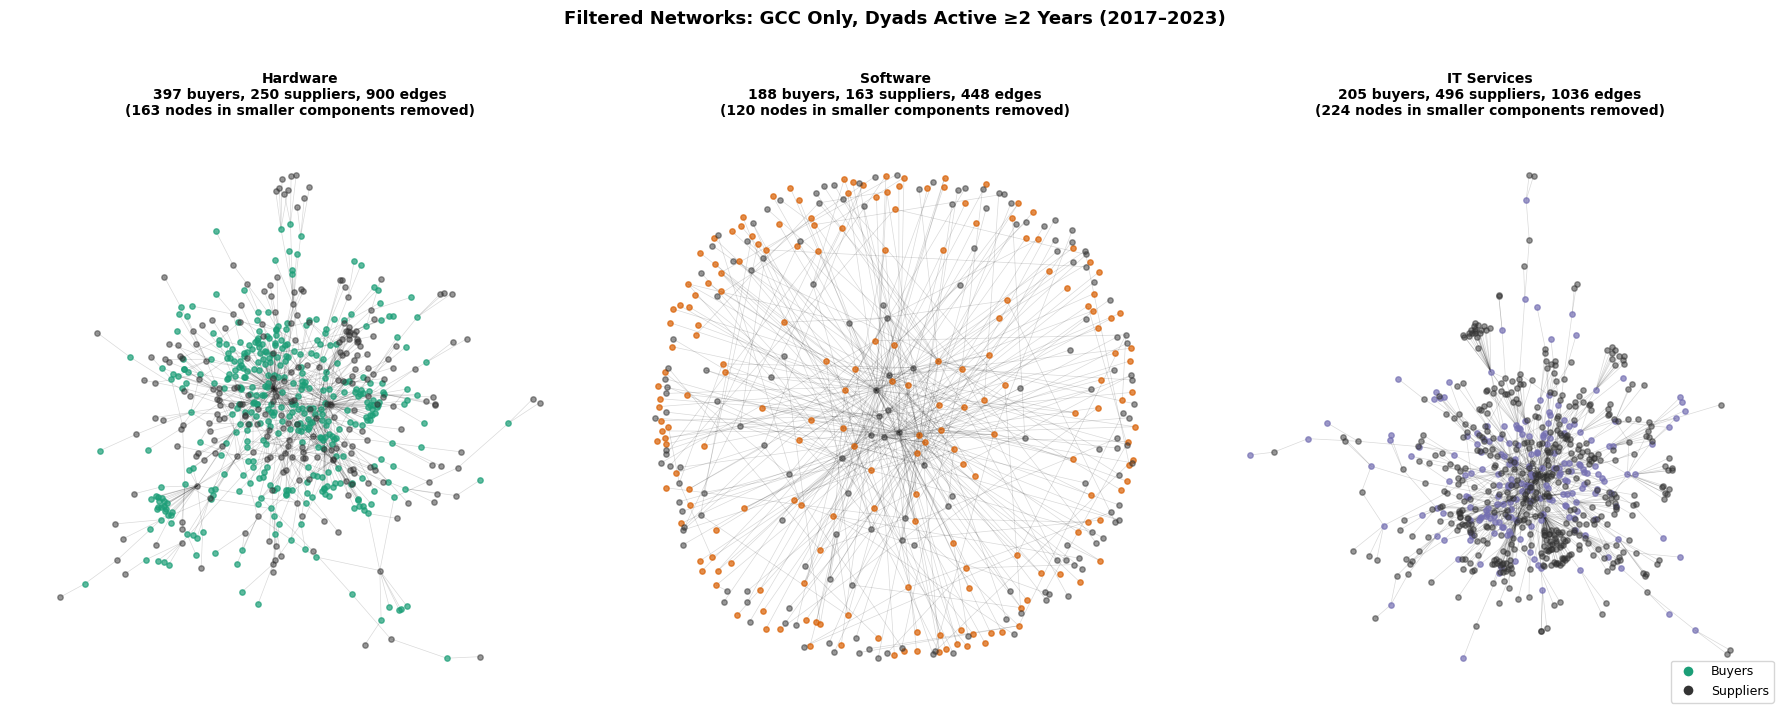

In [16]:
# -----------------------------------------------------------
# Filtered networks: GCC only
# -----------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 7))

for ax, seg in zip(axes, ["30", "48", "72"]):
    seg_df = df17[df17["cpv_segments_str"].str.contains(seg)]
    
    persistence = seg_df.groupby(["CAE_NAME_CANONICAL", "WIN_NAME_FINAL"]).size()
    backbone_dyads = persistence[persistence >= THRESHOLD].reset_index()
    backbone_dyads.columns = ["buyer", "supplier", "n_years"]
    
    B = nx.Graph()
    for _, row in backbone_dyads.iterrows():
        B.add_edge(f"B_{row['buyer']}", f"S_{row['supplier']}", weight=row["n_years"])
    
    # Extract GCC
    gcc_nodes = max(nx.connected_components(B), key=len)
    G = B.subgraph(gcc_nodes).copy()
    
    buyers_gcc = [n for n in G.nodes() if n.startswith("B_")]
    suppliers_gcc = [n for n in G.nodes() if n.startswith("S_")]
    n_removed = B.number_of_nodes() - G.number_of_nodes()
    
    pos = nx.spring_layout(G, k=0.8, iterations=50, seed=42)
    
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.15, width=0.5)
    nx.draw_networkx_nodes(G, pos, nodelist=buyers_gcc, node_size=15,
                           node_color=seg_colors[seg], alpha=0.7, ax=ax)
    nx.draw_networkx_nodes(G, pos, nodelist=suppliers_gcc, node_size=15,
                           node_color="#333333", alpha=0.5, ax=ax)
    
    ax.set_title(f"{seg_labels[seg]}\n{len(buyers_gcc)} buyers, "
                 f"{len(suppliers_gcc)} suppliers, {G.number_of_edges()} edges\n"
                 f"({n_removed} nodes in smaller components removed)",
                 fontsize=10, fontweight="bold")
    ax.axis("off")

legend_elements = [Line2D([0], [0], marker="o", color="w", markerfacecolor=seg_colors["30"],
                          markersize=8, label="Buyers"),
                   Line2D([0], [0], marker="o", color="w", markerfacecolor="#333333",
                          markersize=8, label="Suppliers")]
axes[2].legend(handles=legend_elements, fontsize=9, loc="lower right")

fig.suptitle(f"Filtered Networks: GCC Only, Dyads Active ≥{THRESHOLD} Years (2017–2023)",
             fontsize=13, fontweight="bold", y=1.02)
fig.tight_layout()
plt.savefig("graphs_tables/desc_filtered_gcc.png", dpi=200, bbox_inches="tight")
plt.show()

             Giant component  Isolated pairs (2)  Small (3–10)
Segment                                                       
Hardware               0.799               0.114         0.088
Software               0.745               0.191         0.064
IT Services            0.758               0.164         0.078


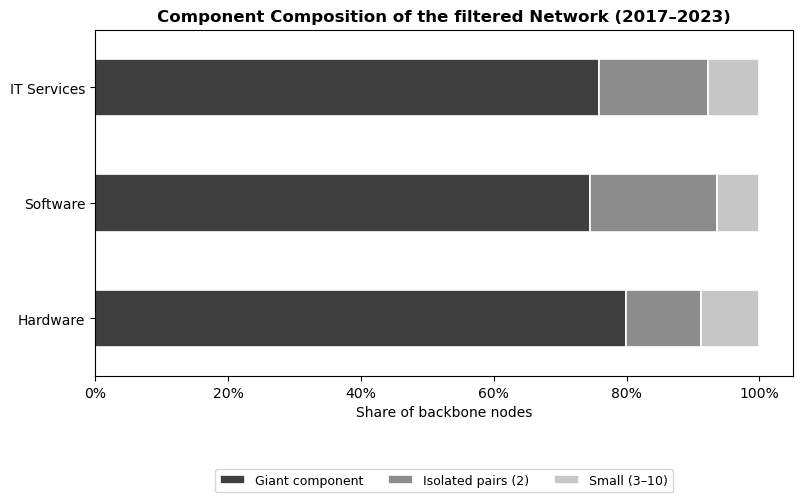

In [17]:
# Component composition per segment: comparable by construction, since every
# bar sums to 100% of that segment's filtered nodes.
size_bins = {"Isolated pairs (2)": lambda n: n == 2,
             "Small (3–10)": lambda n: 3 <= n <= 10}

rows = []
for seg in ["30", "48", "72"]:
    seg_df = df17[df17["cpv_segments_str"].str.contains(seg)]
    persistence = seg_df.groupby(["CAE_NAME_CANONICAL", "WIN_NAME_FINAL"]).size()
    dyads = persistence[persistence >= THRESHOLD].reset_index()
    dyads.columns = ["buyer", "supplier", "n_years"]

    B = nx.Graph()
    B.add_edges_from((f"B_{b}", f"S_{s}") for b, s, _ in dyads.itertuples(index=False))

    comps = sorted(nx.connected_components(B), key=len, reverse=True)
    total = B.number_of_nodes()
    rest = comps[1:]

    entry = {"Segment": seg_labels[seg], "Giant component": len(comps[0]) / total}
    for label, test in size_bins.items():
        entry[label] = sum(len(c) for c in rest if test(len(c))) / total
    rows.append(entry)

comp_comp = pd.DataFrame(rows).set_index("Segment")
print(comp_comp.round(3))

ax = comp_comp.plot(kind="barh", stacked=True, figsize=(9, 4.5),
                    color=["#3f3f3f", "#8c8c8c", "#c6c6c6"],
                    edgecolor="white", linewidth=1.2)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
ax.set_xlabel("Share of backbone nodes")
ax.set_ylabel("")
ax.legend(fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=4)
ax.set_title("Component Composition of the filtered Network (2017–2023)",
             fontsize=12, fontweight="bold")

plt.savefig("graphs_tables/desc_comp_comp_filted.png", dpi=200, bbox_inches="tight")
plt.show()

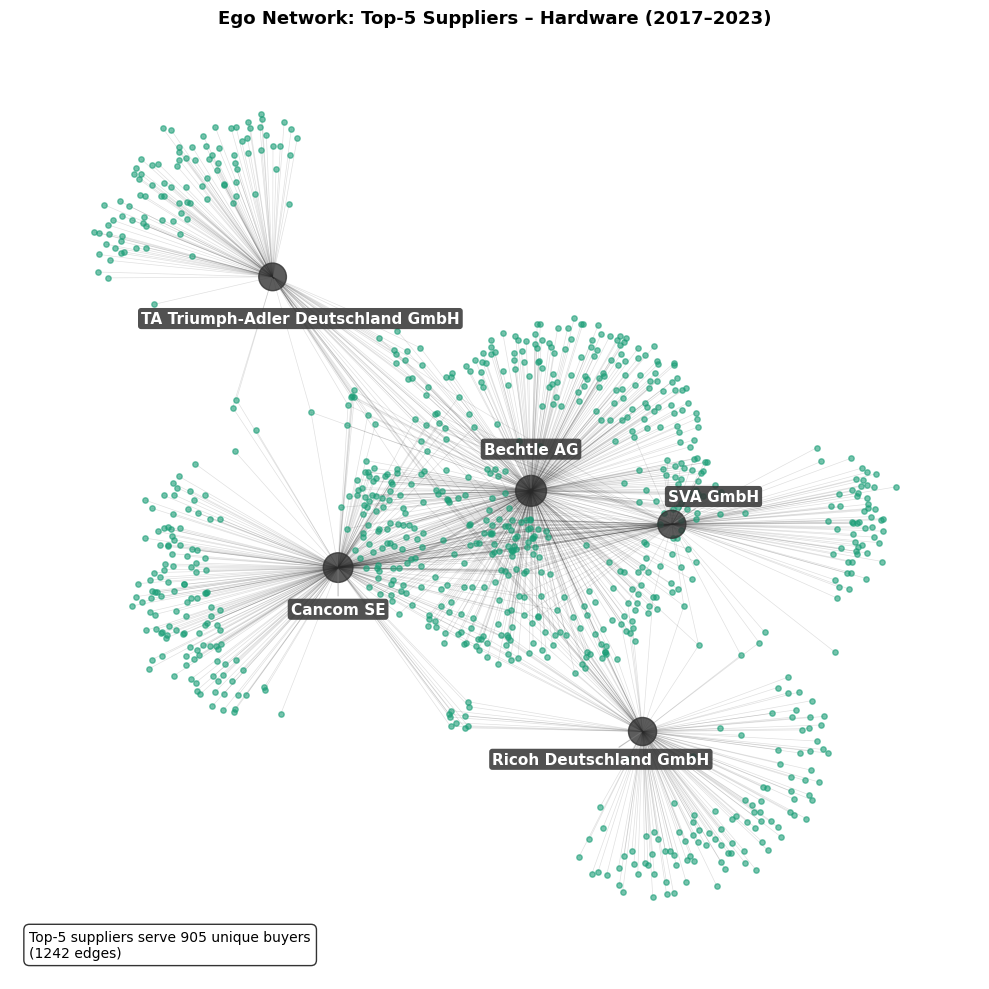

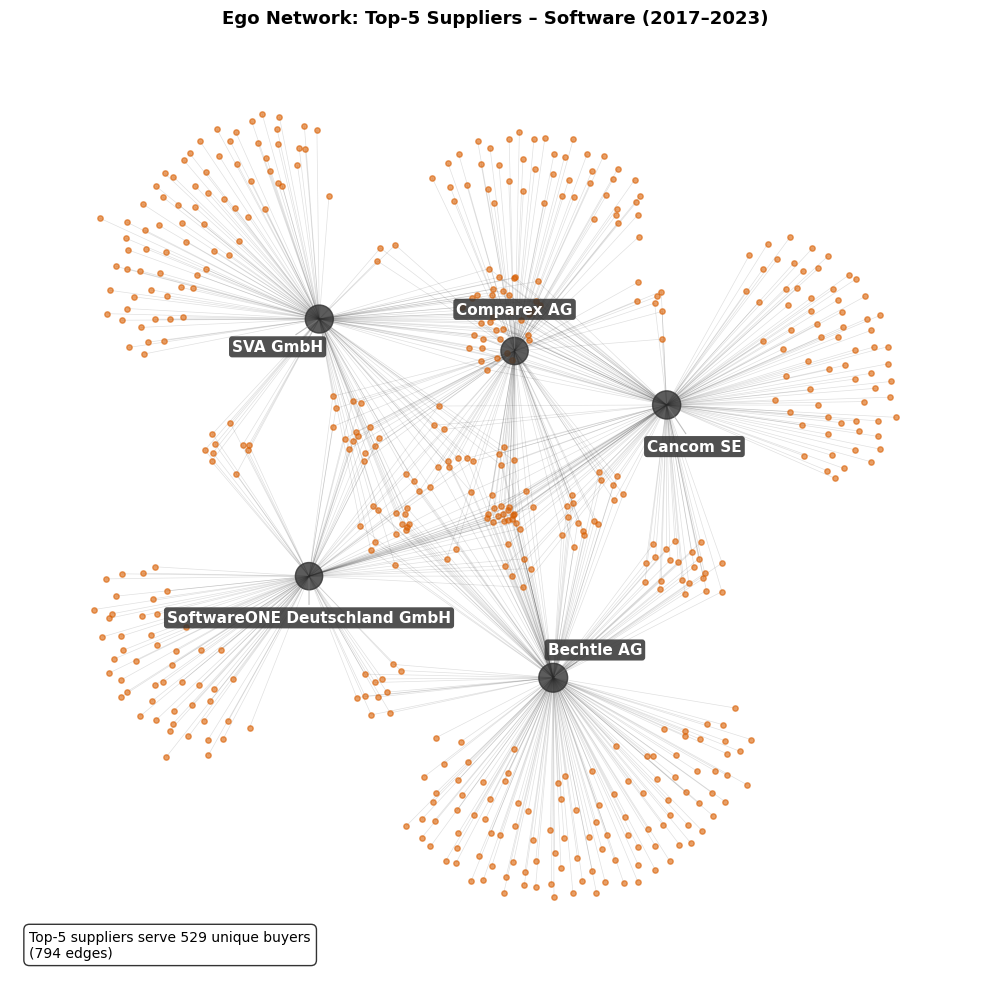

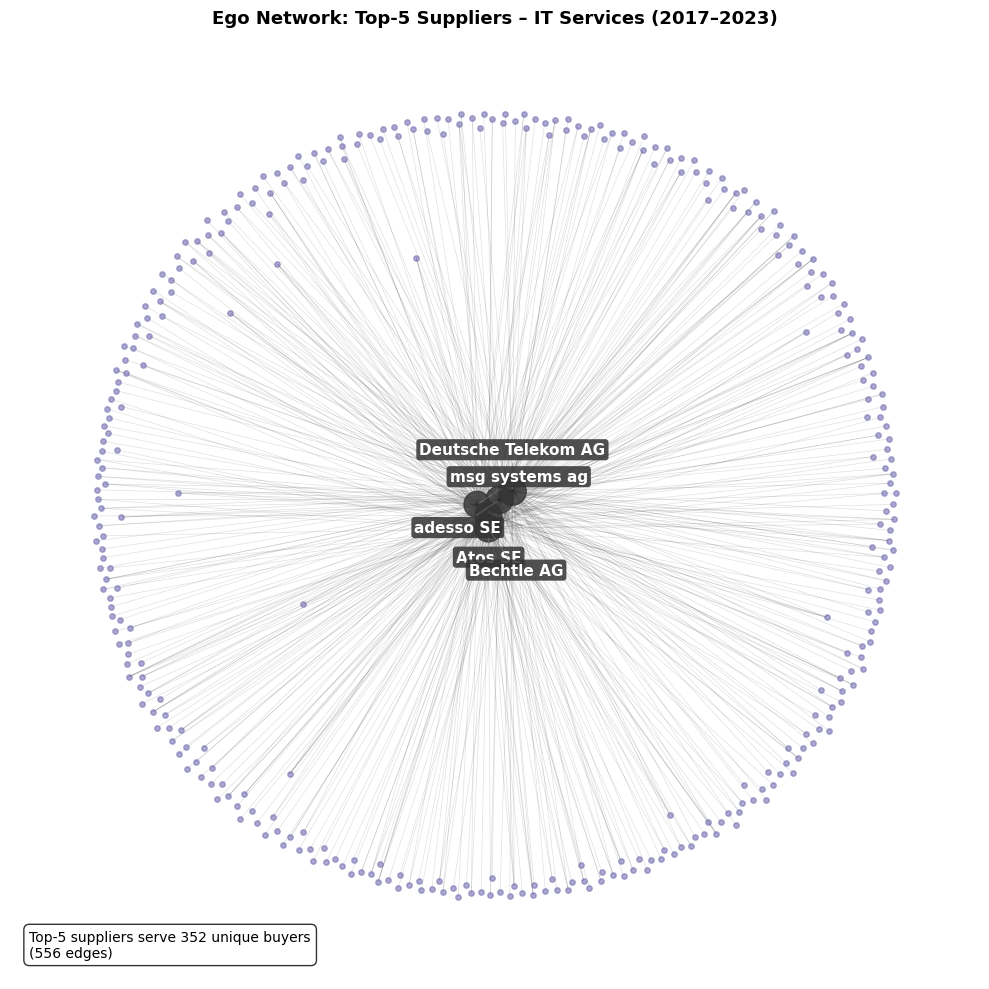

In [18]:
# -----------------------------------------------------------
# Ego networks: Top-5 suppliers per segment (separate plots, final)
# -----------------------------------------------------------
layout_params = {
    "30": {"k": 1.5, "iterations": 80},
    "48": {"k": 1.5, "iterations": 80},
    "72": {"k": 3.0, "iterations": 150},
}
# Staggered x/y offsets to prevent overlap
label_offsets = [(0, 30), (0, -30), (30, 20), (-30, -20), (20, -30)]

for seg in ["30", "48", "72"]:
    seg_df = df17[df17["cpv_segments_str"].str.contains(seg)]
    
    supplier_deg = seg_df.groupby("WIN_NAME_FINAL")["CAE_NAME_CANONICAL"].nunique()
    top5 = supplier_deg.nlargest(5).index.tolist()
    
    ego_df = seg_df[seg_df["WIN_NAME_FINAL"].isin(top5)].drop_duplicates(
        subset=["CAE_NAME_CANONICAL", "WIN_NAME_FINAL"])
    
    E = nx.Graph()
    for _, row in ego_df.iterrows():
        E.add_edge(f"B_{row['CAE_NAME_CANONICAL']}", f"S_{row['WIN_NAME_FINAL']}")
    
    buyers_ego = [n for n in E.nodes() if n.startswith("B_")]
    suppliers_ego = [n for n in E.nodes() if n.startswith("S_")]
    supplier_sizes = [np.log1p(E.degree(n)) * 80 for n in suppliers_ego]
    
    fig, ax = plt.subplots(figsize=(10, 10))
    
    params = layout_params[seg]
    pos = nx.spring_layout(E, k=params["k"], iterations=params["iterations"], seed=42)
    
    nx.draw_networkx_edges(E, pos, ax=ax, alpha=0.12, width=0.5)
    nx.draw_networkx_nodes(E, pos, nodelist=buyers_ego, node_size=15,
                           node_color=seg_colors[seg], alpha=0.6, ax=ax)
    nx.draw_networkx_nodes(E, pos, nodelist=suppliers_ego, node_size=supplier_sizes,
                           node_color="#333333", alpha=0.8, ax=ax)
    
    supplier_labels = {n: n.replace("S_", "") for n in suppliers_ego}
    for i, n in enumerate(suppliers_ego):
        ox, oy = label_offsets[i % len(label_offsets)]
        ax.annotate(supplier_labels[n], xy=pos[n], xytext=(ox, oy),
                    textcoords="offset points", fontsize=11, fontweight="bold",
                    color="white", ha="center", va="center",
                    arrowprops=dict(arrowstyle="-", color="grey", alpha=0.5, lw=0.8),
                    bbox=dict(boxstyle="round,pad=0.2", facecolor="#333333",
                              edgecolor="none", alpha=0.85))
    
    ax.text(0.02, 0.02,
            f"Top-5 suppliers serve {len(buyers_ego)} unique buyers\n"
            f"({E.number_of_edges()} edges)",
            transform=ax.transAxes, fontsize=10, va="bottom",
            bbox=dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.8))
    
    ax.set_title(f"Ego Network: Top-5 Suppliers – {seg_labels[seg]} (2017–2023)",
                 fontsize=13, fontweight="bold")
    ax.axis("off")
    
    fig.tight_layout()
    plt.savefig(f"graphs_tables/desc_ego_top5_cpv{seg}.png", dpi=200, bbox_inches="tight")
    plt.show()

In [19]:
# -----------------------------------------------------------
# Top-10 suppliers and buyers per segment with shares (2017–2023)
# -----------------------------------------------------------
for seg in ["30", "48", "72"]:
    seg_df = df17[df17["cpv_segments_str"].str.contains(seg)]
    dyads = seg_df.drop_duplicates(subset=["CAE_NAME_CANONICAL", "WIN_NAME_FINAL"])
    
    total_buyers = dyads["CAE_NAME_CANONICAL"].nunique()
    total_suppliers = dyads["WIN_NAME_FINAL"].nunique()
    total_edges = len(dyads)
    
    # Top-10 suppliers
    sup_deg = (dyads.groupby("WIN_NAME_FINAL")["CAE_NAME_CANONICAL"].nunique()
               .sort_values(ascending=False).head(10)
               .reset_index())
    sup_deg.columns = ["Supplier", "n_buyers"]
    sup_deg["% of buyers reached"] = (sup_deg["n_buyers"] / total_buyers).map("{:.1%}".format)
    sup_deg["% of edges"] = (sup_deg["n_buyers"] / total_edges).map("{:.1%}".format)
    
    # Top-10 buyers
    buy_deg = (dyads.groupby("CAE_NAME_CANONICAL")["WIN_NAME_FINAL"].nunique()
               .sort_values(ascending=False).head(10)
               .reset_index())
    buy_deg.columns = ["Buyer", "n_suppliers"]
    buy_deg["% of suppliers reached"] = (buy_deg["n_suppliers"] / total_suppliers).map("{:.1%}".format)
    buy_deg["% of edges"] = (buy_deg["n_suppliers"] / total_edges).map("{:.1%}".format)
    
    print(f"\n{'='*90}")
    print(f"CPV {seg} - {seg_labels[seg]}  ({total_buyers:,} buyers, {total_suppliers:,} suppliers, {total_edges:,} edges)")
    print(f"{'='*90}")
    print(f"\nTop-10 Suppliers:")
    print(sup_deg.to_string(index=False))
    print(f"\nTop-10 Buyers:")
    print(buy_deg.to_string(index=False))


CPV 30 - Hardware  (2,353 buyers, 2,250 suppliers, 7,917 edges)

Top-10 Suppliers:
                             Supplier  n_buyers % of buyers reached % of edges
                           Bechtle AG       479               20.4%       6.1%
                            Cancom SE       296               12.6%       3.7%
               Ricoh Deutschland GmbH       166                7.1%       2.1%
                             SVA GmbH       161                6.8%       2.0%
    TA Triumph-Adler Deutschland GmbH       140                5.9%       1.8%
              Lyreco Deutschland GmbH       127                5.4%       1.6%
                    ITMediaConsult AG       115                4.9%       1.5%
                  Deutsche Telekom AG       115                4.9%       1.5%
Gesellschaft für digitale Bildung mbH       102                4.3%       1.3%
                            Rednet AG        95                4.0%       1.2%

Top-10 Buyers:
                               

In [20]:
# -----------------------------------------------------------
# Market concentration: Top-10 share of total connections
# -----------------------------------------------------------
for seg in ["30", "48", "72"]:
    seg_df = df17[df17["cpv_segments_str"].str.contains(seg)]
    
    # Unique dyads (not dyad-years)
    dyads = seg_df.drop_duplicates(subset=["CAE_NAME_CANONICAL", "WIN_NAME_FINAL"])
    total_edges = len(dyads)
    
    # Supplier side
    sup_deg = dyads.groupby("WIN_NAME_FINAL").size().sort_values(ascending=False)
    sup_top10 = sup_deg.head(10)
    sup_top5 = sup_deg.head(5)
    sup_top1 = sup_deg.head(1)
    
    # Buyer side
    buy_deg = dyads.groupby("CAE_NAME_CANONICAL").size().sort_values(ascending=False)
    buy_top10 = buy_deg.head(10)
    buy_top5 = buy_deg.head(5)
    buy_top1 = buy_deg.head(1)
    
    print(f"\n{'='*60}")
    print(f"CPV {seg} – {seg_labels[seg]}  (total unique dyads: {total_edges:,})")
    print(f"{'='*60}")
    
    print(f"\n  Suppliers:")
    print(f"    Top-1:  {sup_top1.sum():>5} connections = {sup_top1.sum()/total_edges:.1%}")
    print(f"    Top-5:  {sup_top5.sum():>5} connections = {sup_top5.sum()/total_edges:.1%}")
    print(f"    Top-10: {sup_top10.sum():>5} connections = {sup_top10.sum()/total_edges:.1%}")
    print(f"    Total suppliers: {len(sup_deg):,}")
    
    print(f"\n  Buyers:")
    print(f"    Top-1:  {buy_top1.sum():>5} connections = {buy_top1.sum()/total_edges:.1%}")
    print(f"    Top-5:  {buy_top5.sum():>5} connections = {buy_top5.sum()/total_edges:.1%}")
    print(f"    Top-10: {buy_top10.sum():>5} connections = {buy_top10.sum()/total_edges:.1%}")
    print(f"    Total buyers: {len(buy_deg):,}")


CPV 30 – Hardware  (total unique dyads: 7,917)

  Suppliers:
    Top-1:    479 connections = 6.1%
    Top-5:   1242 connections = 15.7%
    Top-10:  1796 connections = 22.7%
    Total suppliers: 2,250

  Buyers:
    Top-1:     68 connections = 0.9%
    Top-5:    251 connections = 3.2%
    Top-10:   415 connections = 5.2%
    Total buyers: 2,353

CPV 48 – Software  (total unique dyads: 5,888)

  Suppliers:
    Top-1:    217 connections = 3.7%
    Top-5:    794 connections = 13.5%
    Top-10:  1195 connections = 20.3%
    Total suppliers: 2,355

  Buyers:
    Top-1:     93 connections = 1.6%
    Top-5:    364 connections = 6.2%
    Top-10:   613 connections = 10.4%
    Total buyers: 2,013

CPV 72 – IT Services  (total unique dyads: 9,157)

  Suppliers:
    Top-1:    143 connections = 1.6%
    Top-5:    556 connections = 6.1%
    Top-10:   867 connections = 9.5%
    Total suppliers: 4,257

  Buyers:
    Top-1:    232 connections = 2.5%
    Top-5:    819 connections = 8.9%
    Top-10:  12

In [21]:
# -----------------------------------------------------------
# Market concentration: export Table (concentration) as .tex
# -----------------------------------------------------------
SEG_DISPLAY = {"30": ("Hardware", "CPV 30"),
               "48": ("Software", "CPV 48"),
               "72": ("IT services", "CPV 72")}
SEGS = ["30", "48", "72"]

conc = {}
for seg in SEGS:
    seg_df = df17[df17["cpv_segments_str"].str.contains(seg)]
    dyads = seg_df.drop_duplicates(subset=["CAE_NAME_CANONICAL", "WIN_NAME_FINAL"])
    total_edges = len(dyads)

    sup_deg = dyads.groupby("WIN_NAME_FINAL").size().sort_values(ascending=False)
    buy_deg = dyads.groupby("CAE_NAME_CANONICAL").size().sort_values(ascending=False)

    conc[seg] = {
        "sup_top1": sup_deg.head(1).sum() / total_edges * 100,
        "sup_top5": sup_deg.head(5).sum() / total_edges * 100,
        "sup_top10": sup_deg.head(10).sum() / total_edges * 100,
        "buy_top1": buy_deg.head(1).sum() / total_edges * 100,
        "buy_top5": buy_deg.head(5).sum() / total_edges * 100,
        "buy_top10": buy_deg.head(10).sum() / total_edges * 100,
        "n_dyads": total_edges,
        "n_sup": len(sup_deg),
        "n_buy": len(buy_deg),
    }

def _row(label, key, fmt="{:.1f}"):
    cells = " & ".join(fmt.format(conc[s][key]) for s in SEGS)
    return f"\\quad {label} & {cells} \\\\"

lines = [
    r"\begin{table}[htbp]",
    r"\centering",
    r"\begin{threeparttable}",
    r"\caption{Concentration of relationships by segment, 2017--2023}",
    r"\label{tab:concentration}",
    r"\begin{tabular}{lrrr}",
    r"\toprule",
    " & " + " & ".join(SEG_DISPLAY[s][0] for s in SEGS) + r" \\",
    " & " + " & ".join(f"({SEG_DISPLAY[s][1]})" for s in SEGS) + r" \\",
    r"\midrule",
    r"\multicolumn{4}{l}{\emph{Share of all relationships held by the largest"
    r" suppliers (\%)}} \\",
    _row("Largest supplier", "sup_top1"),
    _row("Five largest", "sup_top5"),
    _row("Ten largest", "sup_top10"),
    r"\addlinespace",
    r"\multicolumn{4}{l}{\emph{Share of all relationships held by the largest"
    r" buyers (\%)}} \\",
    _row("Largest buyer", "buy_top1"),
    _row("Five largest", "buy_top5"),
    _row("Ten largest", "buy_top10"),
    r"\addlinespace",
    r"\multicolumn{4}{l}{\emph{Segment size}} \\",
    _row("Distinct relationships", "n_dyads", "{:,.0f}"),
    _row("Suppliers", "n_sup", "{:,.0f}"),
    _row("Buyers", "n_buy", "{:,.0f}"),
    r"\bottomrule",
    r"\end{tabular}",
    r"\begin{tablenotes}[flushleft]",
    r"\footnotesize",
    r"\item \textit{Note.} A relationship is a distinct buyer--supplier pair "
    r"observed at least once between 2017 and 2023; repeated awards within a "
    r"pair are counted once. Shares on both sides are expressed as a proportion "
    r"of the same total, so supplier and buyer concentration are directly "
    r"comparable. All buyers and suppliers with at least one award in the "
    r"segment are included; no degree filter is applied.",
    r"\end{tablenotes}",
    r"\end{threeparttable}",
    r"\end{table}",
]

with open("results/tab_concentration.tex", "w", encoding="utf-8") as f:
    f.write("\n".join(lines) + "\n")

print("Done.")
print("\n".join(lines))

Done.
\begin{table}[htbp]
\centering
\begin{threeparttable}
\caption{Concentration of relationships by segment, 2017--2023}
\label{tab:concentration}
\begin{tabular}{lrrr}
\toprule
 & Hardware & Software & IT services \\
 & (CPV 30) & (CPV 48) & (CPV 72) \\
\midrule
\multicolumn{4}{l}{\emph{Share of all relationships held by the largest suppliers (\%)}} \\
\quad Largest supplier & 6.1 & 3.7 & 1.6 \\
\quad Five largest & 15.7 & 13.5 & 6.1 \\
\quad Ten largest & 22.7 & 20.3 & 9.5 \\
\addlinespace
\multicolumn{4}{l}{\emph{Share of all relationships held by the largest buyers (\%)}} \\
\quad Largest buyer & 0.9 & 1.6 & 2.5 \\
\quad Five largest & 3.2 & 6.2 & 8.9 \\
\quad Ten largest & 5.2 & 10.4 & 13.7 \\
\addlinespace
\multicolumn{4}{l}{\emph{Segment size}} \\
\quad Distinct relationships & 7,917 & 5,888 & 9,157 \\
\quad Suppliers & 2,250 & 2,355 & 4,257 \\
\quad Buyers & 2,353 & 2,013 & 2,116 \\
\bottomrule
\end{tabular}
\begin{tablenotes}[flushleft]
\footnotesize
\item \textit{Note.} A 